# ALiBi refinement at 48, 108, and 192 spins

We extend the 12-spin refinement to periodic Kagome **L=4,6,8**, with
**48,108,192 spins**, respectively. Every comparison within a size uses the
same positive-random AF bonds (disorder ID 0), Γ=0.5, and h=0.3.

**Completed result:** both seeds lower the energy at every size. The refined
energy per spin is approximately −1.09727 (48 spins), −1.11604 (108 spins),
and −1.06935 (192 spins). These are improvements relative to the original
shared model, not errors relative to an exact reference.

The independent observable audit finds raw-overlap and connected-χ seed
differences within about 1.3 combined sampling standard errors at 48/108 spins.
At 192 spins, raw overlap is **0.48053 vs 0.47289** and connected χ is
**0.22159 vs 0.23322**, with differences about 13.4 and 4.3 combined sampling
standard errors. Magnetization differences are resolved at all sizes.
**The 192-spin observables are not yet stable across optimization seeds.**
Additional optimization/capacity and projection checks remain necessary;
energy agreement alone is insufficient.

Each Hamiltonian receives **two independent sampled-VMC refinements**, seeds
201 and 202, initialized from the original shared ALiBi model. We preserve the
width-32 architecture, two causal blocks, four heads, and the static context
encoder. Each run uses 2,400 updates, batch 128, and Adam with learning rate
0.0005→0.00005. The 12-site-specialized checkpoint is not used here.

**The predeclared final checkpoint is evaluated**, avoiding selection of a
checkpoint using a noisy energy minimum. Both seeds are shown. Final estimates
use 32 independent batches of 256 configurations (8,192 energy samples), plus
independent four-replica draws for the observables. Interim evaluations use
separate random streams. Exact diagonalization is unavailable at these sizes.

Read the results as follows:

- Lower energy at the **same Hamiltonian** is a variational improvement if
  the difference is resolved relative to its sampling error.
- Lower local-energy variance is useful evidence but does not certify a
  ground state; an excited eigenstate also has zero variance.
- Compare raw overlap and connected susceptibility across training seeds.
  Differences beyond sampling error indicate residual variational sensitivity.
- Neither seed agreement nor a training plateau establishes ground-state
  convergence. Projection and population checks remain necessary.

The earlier fixed-position models and original shared ALiBi model are baselines
with different training budgets. This comparison does not isolate ALiBi's effect.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT=Path.cwd()
if not (ROOT/'code/transformer_qmc').exists():
    ROOT=ROOT.parent
RESULTS=ROOT/'data/kagome/transformer_af_alibi_sizes_v1'
BASELINE=ROOT/'data/kagome/transformer_af_dual_v1'
summary=json.loads((RESULTS/'summary.json').read_text())
status=json.loads((RESULTS/'status.json').read_text())
display(Markdown(f"**Campaign state:** {status['state']}; {len(summary)}/6 final evaluations downloaded."))
shared={r['L']:r['vmc'] for r in json.loads((BASELINE/'unified_alibi/evaluation.json').read_text()) if r['sample_id']==0}
fixed={L:[] for L in (4,6,8)}
for path in sorted((BASELINE/'fixed_size').glob('*/evaluation.json')):
    s=json.loads((path.parent/'settings.json').read_text())
    if s['L'] in fixed and s['gamma']==.5 and s['h']==.3:
        fixed[s['L']].append((s['train_seed'],json.loads(path.read_text())))
table=['| Spins | Model | Energy/spin ± SE | Variance/N | Raw q² ± SE | Connected χ ± SE |',
       '|---:|---|---:|---:|---:|---:|']
def row(n,label,r):
    def value(key,scale=1):
        return f"{r[key]['mean']/scale:.6f} ± {r[key]['se']/scale:.6f}"
    return f"| {n} | {label} | {value('energy',n)} | {r['local_energy_variance']/n:.6f} | {value('q2')} | {value('chi_connected')} |"
for L in (4,6,8):
    n=3*L*L
    table.append(row(n,'Original shared ALiBi',shared[L]))
    for seed,r in fixed[L]:
        table.append(row(n,f'Earlier fixed, seed {seed}',r))
    for r in summary:
        if r['L']==L:
            table.append(row(n,f"Refined ALiBi, seed {r['seed']}",r['sampled']))
display(Markdown('\n'.join(table)))
display(Markdown('SE denotes Monte Carlo sampling error for the individual variational state, not its unknown error relative to the exact ground state. Variances are point estimates.'))


**Campaign state:** completed; 6/6 final evaluations downloaded.

| Spins | Model | Energy/spin ± SE | Variance/N | Raw q² ± SE | Connected χ ± SE |
|---:|---|---:|---:|---:|---:|
| 48 | Original shared ALiBi | -1.080037 ± 0.000349 | 0.024360 | 0.593249 ± 0.002834 | 0.127035 ± 0.004845 |
| 48 | Earlier fixed, seed 19 | -1.050501 ± 0.000675 | 0.022942 | 0.510746 ± 0.002671 | 0.215129 ± 0.006263 |
| 48 | Refined ALiBi, seed 201 | -1.097286 ± 0.000124 | 0.004831 | 0.554278 ± 0.001629 | 0.177958 ± 0.003230 |
| 48 | Refined ALiBi, seed 202 | -1.097254 ± 0.000099 | 0.005010 | 0.557989 ± 0.001405 | 0.170095 ± 0.003157 |
| 108 | Original shared ALiBi | -1.088752 ± 0.000321 | 0.037283 | 0.579621 ± 0.002261 | 0.147967 ± 0.005326 |
| 108 | Earlier fixed, seed 21 | -1.076243 ± 0.000548 | 0.028186 | 0.567593 ± 0.001581 | 0.141475 ± 0.004498 |
| 108 | Earlier fixed, seed 22 | -1.084195 ± 0.000312 | 0.023627 | 0.597380 ± 0.002361 | 0.130823 ± 0.005946 |
| 108 | Refined ALiBi, seed 201 | -1.116020 ± 0.000127 | 0.011439 | 0.554202 ± 0.000991 | 0.160238 ± 0.002522 |
| 108 | Refined ALiBi, seed 202 | -1.116066 ± 0.000131 | 0.011617 | 0.553316 ± 0.000882 | 0.168177 ± 0.001955 |
| 192 | Original shared ALiBi | -1.034134 ± 0.000425 | 0.063279 | 0.546879 ± 0.001369 | 0.153442 ± 0.004610 |
| 192 | Earlier fixed, seed 24 | -1.054951 ± 0.000269 | 0.038389 | 0.532827 ± 0.001017 | 0.162557 ± 0.005326 |
| 192 | Refined ALiBi, seed 201 | -1.069442 ± 0.000114 | 0.018268 | 0.482442 ± 0.000899 | 0.226911 ± 0.003866 |
| 192 | Refined ALiBi, seed 202 | -1.069249 ± 0.000129 | 0.019464 | 0.472347 ± 0.000659 | 0.229426 ± 0.003019 |

SE denotes Monte Carlo sampling error for the individual variational state, not its unknown error relative to the exact ground state. Variances are point estimates.

In [2]:
table=['| Spins | Seed | ΔE/N versus original shared ± SE | Variance reduction factor |',
       '|---:|---:|---:|---:|']
improvements=[]
for r in summary:
    original=shared[r['L']]
    refined=r['sampled']
    n=r['N']
    delta=(refined['energy']['mean']-original['energy']['mean'])/n
    se=np.hypot(refined['energy']['se'],original['energy']['se'])/n
    factor=original['local_energy_variance']/refined['local_energy_variance']
    table.append(f"| {n} | {r['seed']} | {delta:.6f} ± {se:.6f} | {factor:.2f}× |")
    improvements.append(dict(L=r['L'],N=n,seed=r['seed'],energy_change_per_spin=delta,
                             combined_se=se,variance_reduction=factor))
display(Markdown('\n'.join(table)))
display(Markdown('Negative ΔE means lower energy on the identical Hamiltonian. The ratio of estimated variances is descriptive; it is not a measured projector speedup.'))
(RESULTS/'improvements.json').write_text(json.dumps(improvements,indent=2)+'\n')


| Spins | Seed | ΔE/N versus original shared ± SE | Variance reduction factor |
|---:|---:|---:|---:|
| 48 | 201 | -0.017249 ± 0.000371 | 5.04× |
| 48 | 202 | -0.017217 ± 0.000363 | 4.86× |
| 108 | 201 | -0.027268 ± 0.000345 | 3.26× |
| 108 | 202 | -0.027314 ± 0.000347 | 3.21× |
| 192 | 201 | -0.035308 ± 0.000440 | 3.46× |
| 192 | 202 | -0.035115 ± 0.000444 | 3.25× |

Negative ΔE means lower energy on the identical Hamiltonian. The ratio of estimated variances is descriptive; it is not a measured projector speedup.

1147

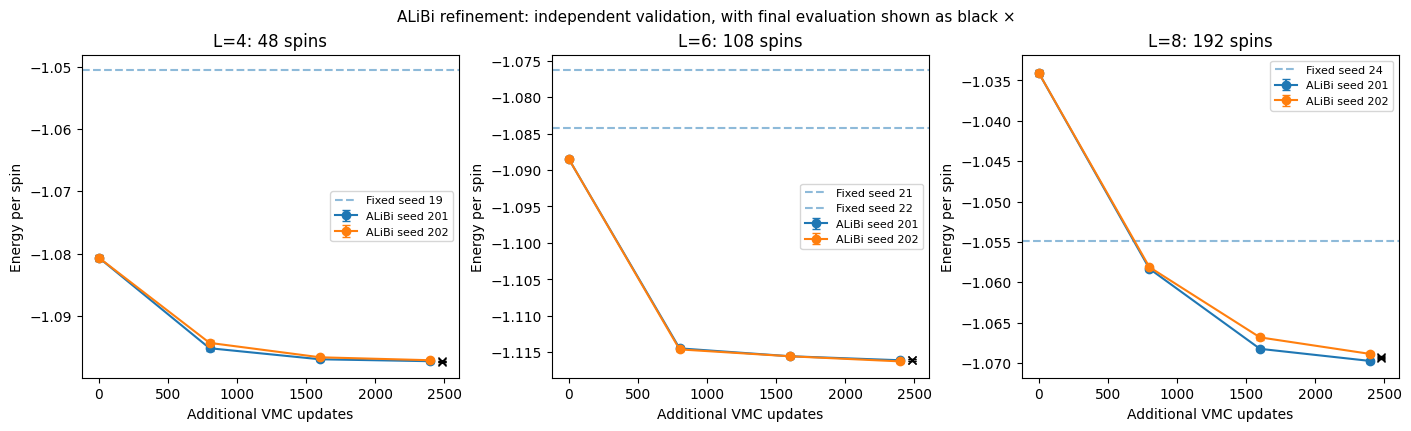

In [3]:
fig,axes=plt.subplots(1,3,figsize=(14,4.2),constrained_layout=True)
for ax,L in zip(axes,(4,6,8)):
    n=3*L*L
    for r in summary:
        if r['L']!=L:
            continue
        directory=RESULTS/Path(r['final_checkpoint']).parent
        trace=json.loads((directory/'validation.json').read_text())
        ax.errorbar([t['step'] for t in trace],
                    [t['sampled']['energy']['mean']/n for t in trace],
                    yerr=[t['sampled']['energy']['se']/n for t in trace],
                    marker='o',capsize=3,label=f"ALiBi seed {r['seed']}")
        ax.errorbar([r['step']+80],[r['sampled']['energy']['mean']/n],
                    yerr=[r['sampled']['energy']['se']/n],fmt='x',color='black',capsize=3)
    for seed,r in fixed[L]:
        ax.axhline(r['energy']['mean']/n,linestyle='--',alpha=.5,label=f'Fixed seed {seed}')
    ax.set(title=f'L={L}: {n} spins',xlabel='Additional VMC updates',ylabel='Energy per spin')
    ax.legend(fontsize=8)
fig.suptitle('ALiBi refinement: independent validation, with final evaluation shown as black ×',fontsize=11)
fig.savefig(RESULTS/'alibi_sizes_energy.png',dpi=180)
fig.savefig(RESULTS/'alibi_sizes_energy.pdf')
plt.show()


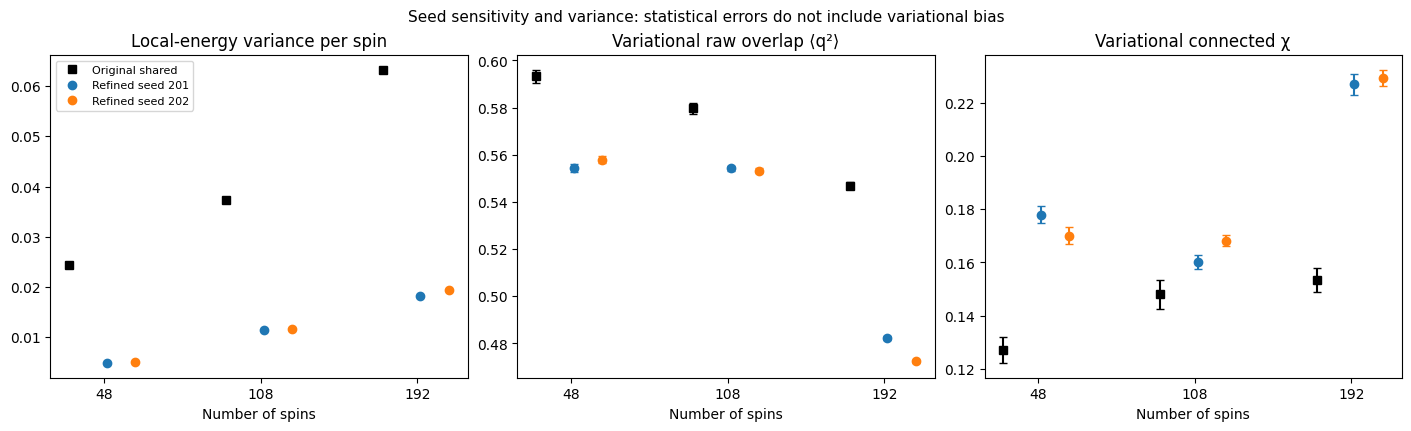

In [4]:
fig,axes=plt.subplots(1,3,figsize=(14,4.2),constrained_layout=True)
for index,L in enumerate((4,6,8)):
    n=3*L*L
    records=[('Original shared',shared[L],index-.22,'black','s')]
    for offset,r in enumerate(sorted([r for r in summary if r['L']==L],key=lambda r:r['seed'])):
        records.append((f"Refined seed {r['seed']}",r['sampled'],index+.02+.18*offset,
                        ['tab:blue','tab:orange'][offset],'o'))
    for label,r,x,color,marker in records:
        axes[0].plot(x,r['local_energy_variance']/n,marker=marker,color=color,
                     linestyle='none',label=label if index==0 else None)
        for ax,key in zip(axes[1:],['q2','chi_connected']):
            ax.errorbar(x,r[key]['mean'],yerr=r[key]['se'],fmt=marker,color=color,capsize=3)
for ax,title in zip(axes,['Local-energy variance per spin','Variational raw overlap ⟨q²⟩','Variational connected χ']):
    ax.set(xticks=range(3),xticklabels=['48','108','192'],xlabel='Number of spins',title=title)
axes[0].legend(fontsize=8)
fig.suptitle('Seed sensitivity and variance: statistical errors do not include variational bias',fontsize=11)
fig.savefig(RESULTS/'alibi_sizes_observables.png',dpi=180)
fig.savefig(RESULTS/'alibi_sizes_observables.pdf')
plt.show()


In [5]:
table=['| Spins | Quantity | Seed 201 − seed 202 | Combined sampling SE | Difference / SE |',
       '|---:|---|---:|---:|---:|']
comparisons=[]
for L in (4,6,8):
    runs=sorted([r for r in summary if r['L']==L],key=lambda r:r['seed'])
    if len(runs)!=2:
        continue
    n=3*L*L
    for key,label in [('energy','Energy/spin'),('q2','Raw q²'),('chi_connected','Connected χ')]:
        a,b=[r['sampled'][key] for r in runs]
        scale=n if key=='energy' else 1
        delta=(a['mean']-b['mean'])/scale
        se=np.hypot(a['se'],b['se'])/scale
        ratio=delta/se if se else None
        table.append(f"| {n} | {label} | {delta:.6g} | {se:.6g} | {ratio:.2f} |")
        comparisons.append(dict(L=L,quantity=key,delta=delta,se=se,difference_over_se=ratio))
display(Markdown('\n'.join(table)))
display(Markdown('These are descriptive differences between two trained states. Ratios well beyond a few sampling standard errors reveal sensitivity; they are not a calibrated multiple-testing procedure or a ground-state error estimate.'))
(RESULTS/'seed_comparisons.json').write_text(json.dumps(comparisons,indent=2)+'\n')


| Spins | Quantity | Seed 201 − seed 202 | Combined sampling SE | Difference / SE |
|---:|---|---:|---:|---:|
| 48 | Energy/spin | -3.17746e-05 | 0.000158668 | -0.20 |
| 48 | Raw q² | -0.00371043 | 0.00215096 | -1.73 |
| 48 | Connected χ | 0.00786336 | 0.00451664 | 1.74 |
| 108 | Energy/spin | 4.62218e-05 | 0.000182277 | 0.25 |
| 108 | Raw q² | 0.000885847 | 0.00132637 | 0.67 |
| 108 | Connected χ | -0.00793909 | 0.00319115 | -2.49 |
| 192 | Energy/spin | -0.000193065 | 0.000172403 | -1.12 |
| 192 | Raw q² | 0.0100951 | 0.00111489 | 9.05 |
| 192 | Connected χ | -0.00251516 | 0.00490488 | -0.51 |

These are descriptive differences between two trained states. Ratios well beyond a few sampling standard errors reveal sensitivity; they are not a calibrated multiple-testing procedure or a ground-state error estimate.

1469

In [6]:
audit_path=RESULTS/'observable_audit.json'
if audit_path.exists():
    audit=json.loads(audit_path.read_text())
    table=['| Spins | Seed | Raw q² ± SE | Connected χ ± SE | Magnetization ± SE |',
           '|---:|---:|---:|---:|---:|']
    for r in audit:
        def estimate(key):
            v=r['observables'][key]
            return f"{v['mean']:.6f} ± {v['se']:.6f}"
        table.append(f"| {3*r['L']**2} | {r['seed']} | {estimate('q2')} | {estimate('chi_connected')} | {estimate('magnetization')} |")
    display(Markdown('### Independent observable audit\n\n32,768 four-replica groups per checkpoint, from fresh sampling streams.\n\n'+'\n'.join(table)))
    for L in (4,6,8):
        pair=sorted([r for r in audit if r['L']==L],key=lambda r:r['seed'])
        if len(pair)==2:
            comparisons=[]
            for key,label in [('q2','raw q²'),('chi_connected','connected χ'),('magnetization','magnetization')]:
                a,b=[r['observables'][key] for r in pair]
                z=(a['mean']-b['mean'])/np.hypot(a['se'],b['se'])
                comparisons.append(f"{label}: **{z:.2f}**")
            display(Markdown(f"L={L}, seed difference / combined sampling SE — "+'; '.join(comparisons)))
else:
    display(Markdown('Independent higher-statistics observable audit not yet downloaded.'))


### Independent observable audit

32,768 four-replica groups per checkpoint, from fresh sampling streams.

| Spins | Seed | Raw q² ± SE | Connected χ ± SE | Magnetization ± SE |
|---:|---:|---:|---:|---:|
| 48 | 201 | 0.556348 ± 0.000814 | 0.174202 ± 0.001481 | 0.127865 ± 0.000164 |
| 48 | 202 | 0.557706 ± 0.000718 | 0.174301 ± 0.001904 | 0.126387 ± 0.000184 |
| 108 | 201 | 0.554597 ± 0.000502 | 0.161904 ± 0.001449 | 0.080549 ± 0.000101 |
| 108 | 202 | 0.554039 ± 0.000493 | 0.164354 ± 0.001410 | 0.078196 ± 0.000102 |
| 192 | 201 | 0.480530 ± 0.000415 | 0.221594 ± 0.001666 | 0.078447 ± 0.000075 |
| 192 | 202 | 0.472888 ± 0.000389 | 0.233215 ± 0.002124 | 0.072330 ± 0.000097 |

L=4, seed difference / combined sampling SE — raw q²: **-1.25**; connected χ: **-0.04**; magnetization: **6.00**

L=6, seed difference / combined sampling SE — raw q²: **0.79**; connected χ: **-1.21**; magnetization: **16.34**

L=8, seed difference / combined sampling SE — raw q²: **13.43**; connected χ: **-4.31**; magnetization: **49.78**

## Checkpoints and next interpretation

All completed final ALiBi checkpoints are retained with explicit L, spin count,
fields, disorder ID, initialization, and seed in the filename. `summary.json`
contains relative final paths and the original latest-archive SHA-256 hashes.
`checkpoint_verification.json` maps both archives to their separate hashes and
records exact equality of their model weights plus local reload/ratio checks.
`campaign.json` records source
hashes and training settings; each run stores its actual bonds and history.

These are Hamiltonian-specific ALiBi guides. There is no assumption that a
specialized checkpoint retains shared-model accuracy on other instances.
Direct transformer ratios are used at all these sizes, without state-space
enumeration. To qualify physical predictions, compare further training/capacity
changes and independent projected estimates with varying projection times,
populations, and branching cadence. A phase boundary cannot be inferred from
these three single-disorder field points.
